# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [82]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Костак Олеся'      # прізвище та ім'я
GROUP        = 'СШІ-32'      # шифр групи, наприклад СШІ-31
NUMBER       = 6       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Костак Олеся | СШІ-32 | номер 6


In [83]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 6   ·   Костак Олеся   ·   СШІ-32

   Ринок:  Cherkasy
   Товар:  молоко   (у наборі даних: Milk - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

In [84]:
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [85]:
import numpy as np
import pandas as pd

In [86]:
# Завдання 1. Підготовка ряду
prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices.head(3)

,ринок,товар,одиниця,валюта,рік,місяць,ціна
0,Cherkasy,Beetroots - Retail,KG,UAH,2014,3,3.6233
1,Cherkasy,Beetroots - Retail,KG,UAH,2014,4,3.8600
2,Cherkasy,Beetroots - Retail,KG,UAH,2014,5,4.2033


In [87]:
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))
prices.head(3)

,ринок,товар,одиниця,валюта,рік,місяць,ціна,date
0,Cherkasy,Beetroots - Retail,KG,UAH,2014,3,3.6233,2014-03-01
1,Cherkasy,Beetroots - Retail,KG,UAH,2014,4,3.8600,2014-04-01
2,Cherkasy,Beetroots - Retail,KG,UAH,2014,5,4.2033,2014-05-01


З варіанту:
   - Ринок:  Cherkasy
   - Товар:  молоко   (у наборі даних: Milk - Retail)

In [88]:
rows = prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)]
print('Одиниця виміру і валюта:', rows['одиниця'].unique(), rows['валюта'].unique())
series = rows.set_index('date')['ціна'].sort_index()
series.head(2)


Одиниця виміру і валюта: <ArrowStringArray>
['L']
Length: 1, dtype: str <ArrowStringArray>
['UAH']
Length: 1, dtype: str


date
2014-03-01    8.4667
2014-04-01    8.5500
Name: ціна, dtype: float64

In [89]:
grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
y_raw = series.reindex(grid)

print('Місяців у сітці:', len(grid))
print('Місяців із виміром:', y_raw.notna().sum())
print('Місяців без виміру:', y_raw.isna().sum())
print('Пропущений місяць:', list(y_raw[y_raw.isna()].index))

Місяців у сітці: 46
Місяців із виміром: 45
Місяців без виміру: 1
Пропущений місяць: [Timestamp('2017-08-01 00:00:00')]


In [90]:
# чи пропуск властивий лише нашому ряду?
print('Рядків у всьому наборі за серпень 2017:', (prices['date'] == '2017-08-01').sum())
count_by_series = prices.groupby(['ринок', 'товар']).size()
print('Рядів у наборі:', len(count_by_series), '| рядів із повними 45 вимірами:', (count_by_series == 45).sum())

Рядків у всьому наборі за серпень 2017: 0
Рядів у наборі: 700 | рядів із повними 45 вимірами: 599


**Висновок до завдання 1:**

Повна місячна сітка з 03.2014 по 12.2017 містить 46 місяців, вимір мають 45 із них. Єдиний пропуск припадає на серпень 2017 року.

Потенційна причина пропуску в самих даних: у всьому наборі немає жодного запису за серпень 2017, що говорить, що це не особливість ринку Черкаси й не помилка моєї сітки, а прогалина у джерелі: цей місяць не зібрали або не опублікували. 

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [91]:
# Завдання 2. Заповнення пропуску
gap = y_raw[y_raw.isna()].index[0]     
i = grid.get_loc(gap)                  

print('Пропуск:', gap.strftime('%m.%Y'))
print('Сусіди: %s = %.4f · %s = %.4f' % (grid[i-1].strftime('%m.%Y'), y_raw.iloc[i-1],
                                         grid[i+1].strftime('%m.%Y'), y_raw.iloc[i+1]))

Пропуск: 08.2017
Сусіди: 07.2017 = 16.9167 · 09.2017 = 16.8267


In [92]:
fill_ffill = y_raw.ffill() # 1) перенесення останнього значення
fill_linear = y_raw.interpolate() # 2) лінійна інтерполяція
fill_cubic = y_raw.interpolate(method='cubic') # 3) кубічний сплайн

table = pd.DataFrame({
    'Спосіб': ['Попереднє значення', 'Лінійна інтерполяція', 'Кубічний сплайн'],
    'Серпень 2017, грн/л': [fill_ffill[gap], fill_linear[gap], fill_cubic[gap]]})
print(table.round(4).to_string(index=False))

              Спосіб  Серпень 2017, грн/л
  Попереднє значення              16.9167
Лінійна інтерполяція              16.8717
     Кубічний сплайн              16.6578


In [93]:
known = y_raw.dropna().index[1:-1]    
err = {'Попереднє значення': [], 'Лінійна інтерполяція': [], 'Кубічний сплайн': []}
for d in known:
    t, true = y_raw.copy(), y_raw[d]
    t[d] = np.nan                     
    err['Попереднє значення'].append(abs(t.ffill()[d] - true))
    err['Лінійна інтерполяція'].append(abs(t.interpolate()[d] - true))
    err['Кубічний сплайн'].append(abs(t.interpolate('cubic')[d] - true))

check = pd.DataFrame({'MAE, грн': {k_: np.mean(v) for k_, v in err.items()},
                      'макс. похибка': {k_: np.max(v) for k_, v in err.items()}}).round(3)
print('Перевірка на %d прихованих місяцях:' % len(known))
print(check.to_string())

Перевірка на 43 прихованих місяцях:
                      MAE, грн  макс. похибка
Попереднє значення       0.273          1.907
Лінійна інтерполяція     0.128          0.927
Кубічний сплайн          0.101          0.599


In [94]:
# обраний спосіб - Кубічний сплайн:
y = y_raw.interpolate(method='cubic')

**Висновок до завдання 2:**

Лінійна інтерполяція вдвічі точніша за «попереднє значення», оскільки метод в прогнозуванні використовує дві сусідні точки, а не одну. Але найкраще себе показав саме кубічний сплайн, де замість однієї прямої через дві точки будується гладка крива, що проходить через усі відомі точки ряду. Результат підтврдився тим, що MAE найменша, тому для прогнозування обрано його. 

Неприпустимо заповнювати пропуск, коли даних немає не випадково, а з причини, яка змінила сам об'єкт. Приклад з цього ж набору: Крим (лише 03.2014), Севастополь (2 місяці), а також Донецька й Луганська області, у яких випали місяці осені 2014 року. Там спостерігати ринок було неможливо, і «заповнені» ціни були б вигадані. Так само не можна заповнювати довгі підряд пропуски або пропуски на краях ряду: це вже не інтерполяція, а вигадування.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

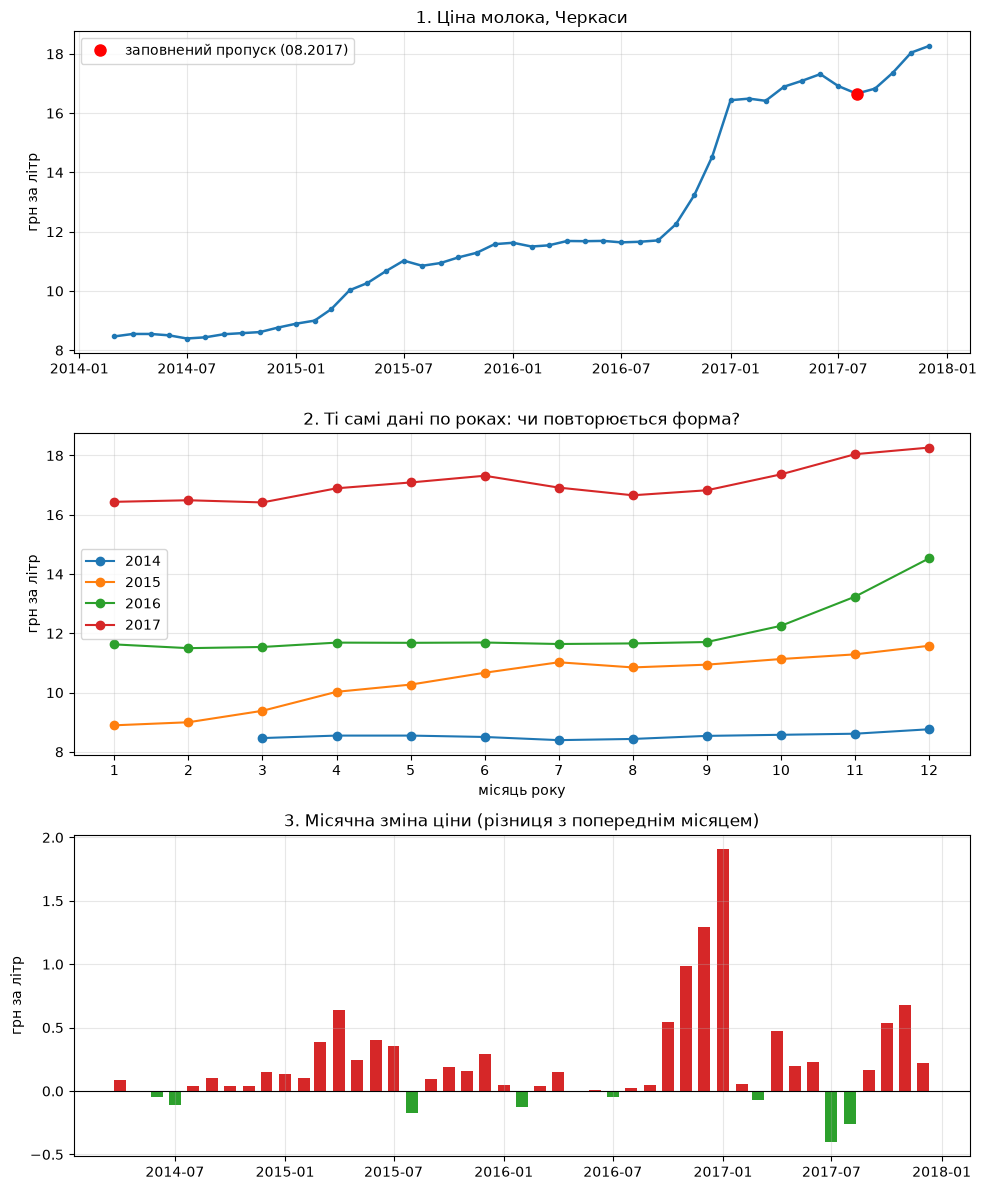

Найбільші місячні зміни:
2017-01-01    1.91
2016-12-01    1.29
2016-11-01    0.98
2017-11-01    0.68
Стандартне відхилення місячних змін: 0.40
Ціна у вер.2016: 11.71, у січ.2017: 16.44, зміна: 40 %
Діапазон грудень 2015 - вересень 2016: 11.50 - 11.71


In [95]:
# Завдання 3. Візуальна розвідка
change = y.diff().dropna()

fig, axes = plt.subplots(3, 1, figsize=(10, 12))

# Графік 1: лінійний графік рівня
axes[0].plot(y.index, y.values, color='tab:blue', lw=1.8)
axes[0].plot(y.index, y.values, 'o', color='tab:blue', ms=3)
axes[0].plot(gap, y[gap], 'o', color='red', ms=8, label='заповнений пропуск (08.2017)')
axes[0].set_title('1. Ціна молока, Черкаси')
axes[0].set_ylabel('грн за літр')
axes[0].legend()

# Графік 2: по роках, вісь x - місяць року
tab = pd.DataFrame({'year': y.index.year, 'month': y.index.month, 'price': y.values})
for year in [2014, 2015, 2016, 2017]:
    part = tab[tab['year'] == year]
    axes[1].plot(part['month'], part['price'], marker='o', label=str(year))
axes[1].set_xticks(range(1, 13))
axes[1].set_title('2. Ті самі дані по роках: чи повторюється форма?')
axes[1].set_xlabel('місяць року')
axes[1].set_ylabel('грн за літр')
axes[1].legend()

# Графік 3: стовпчики місячних змін
colors = []
for v in change.values:
    colors.append('tab:red' if v > 0 else 'tab:green')
axes[2].bar(change.index, change.values, width=20, color=colors)
axes[2].axhline(0, color='black', lw=0.8)
axes[2].set_title('3. Місячна зміна ціни (різниця з попереднім місяцем)')
axes[2].set_ylabel('грн за літр')

plt.tight_layout()
plt.show()

print('Найбільші місячні зміни:')
print(change.nlargest(4).round(2).to_string())
print('Стандартне відхилення місячних змін: %.2f' % change.std())
print('Ціна у вер.2016: %.2f, у січ.2017: %.2f, зміна: %.0f %%' % (y['2016-09-01'], y['2017-01-01'], (y['2017-01-01']/y['2016-09-01']-1)*100))
print('Діапазон грудень 2015 - вересень 2016: %.2f - %.2f' % (y['2015-12-01':'2016-09-01'].min(), y['2015-12-01':'2016-09-01'].max()))

**Висновок до завдання 3:**

Лінійний графік рівня. Питання: як змінювався рівень ціни в часі, чи є стрибки? Лінію обрано тому, що місяці йдуть підряд у часі й ціна рухається неперервно — точки без лінії не показали б напрямок руху.  Заповнений пропуск позначено червоним.

Лінії по роках за місяцем року. Питання: чи повторюється форма в одні й ті самі місяці? Спільна вісь x (місяць) ставить роки один над одним; один колір на рік; спільна вісь y, щоб бачити, що рівень зростає. Видно: влітку є спад (липень 2014, серпень 2015, липень і вересень 2017, між ними заповнений серпень), а 2017 рік майже плоский.
Стовпчики місячних змін. Питання: наскільки великий типовий місячний крок і чи є винятки? Стовпчики, бо зміна відкладається від нуля, і довжина стовпчика чесно означає величину. 

**Несподівана знахідка.** З грудня 2015 до вересня 2016 ціна стояла майже на місці , а потім за 4 місяці виросла на 40 %. 

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

In [96]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL

stl = STL(y, period=12).fit()
trend, seasonal, resid = stl.trend, stl.seasonal, stl.resid

F_S = max(0, 1 - resid.var() / (seasonal + resid).var())
F_T = max(0, 1 - resid.var() / (trend + resid).var())

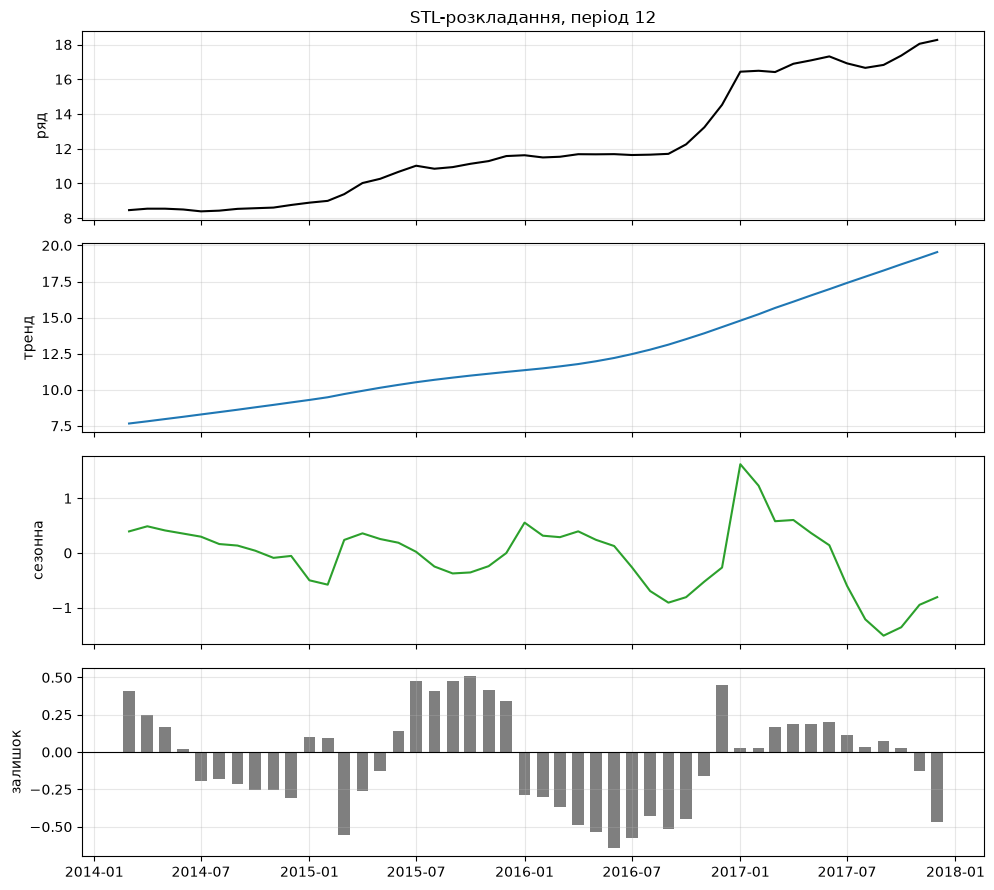

In [97]:
fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
axes[0].plot(y.index, y.values, color='black');  axes[0].set_ylabel('ряд')
axes[1].plot(trend.index, trend.values, color='tab:blue'); axes[1].set_ylabel('тренд')
axes[2].plot(seasonal.index, seasonal.values, color='tab:green'); axes[2].set_ylabel('сезонна')
axes[3].bar(resid.index, resid.values, width=20, color='tab:gray'); axes[3].set_ylabel('залишок')
axes[3].axhline(0, color='black', lw=0.8)
axes[0].set_title('STL-розкладання, період 12')
plt.tight_layout()
plt.show()

In [98]:
print('Сила сезонності F_S = %.3f' % F_S)
print('Сила тренду     F_T = %.3f' % F_T)
print()

threshold = 0.6

if F_S >= threshold:
    print('Сезонність виражена')
else:
    print('Сезонність слабка або помірна')

Сила сезонності F_S = 0.787
Сила тренду     F_T = 0.991

Сезонність виражена


**Висновок до завдання 4:**

Часовий ряд характеризується дуже сильним висхідним трендом (F_T = 0.991) та вираженою сезонністю (F_S = 0.787), що перевищує обраний поріг (0.6). Це свідчить про те, що значення ряду мають стійку довгострокову тенденцію до зростання, а також зазнають помітних сезонних коливань. Отже, під час моделювання та прогнозування необхідно враховувати обидві складові, причому особливу увагу варто приділити тренду.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

Лаг 1 - це залежність від попереднього спостереження, лаг 2 - від спостереження два кроки тому тощо.

ACF показує кореляцію ряду із самим собою, зсунутим на k місяців. PACF робить те саме, але прибирає вплив проміжних лагів, тобто показує «чистий» зв'язок із лагом k.

Синя смуга на графіку це межа значущості: стовпчики за її межами означають значущу кореляцію.

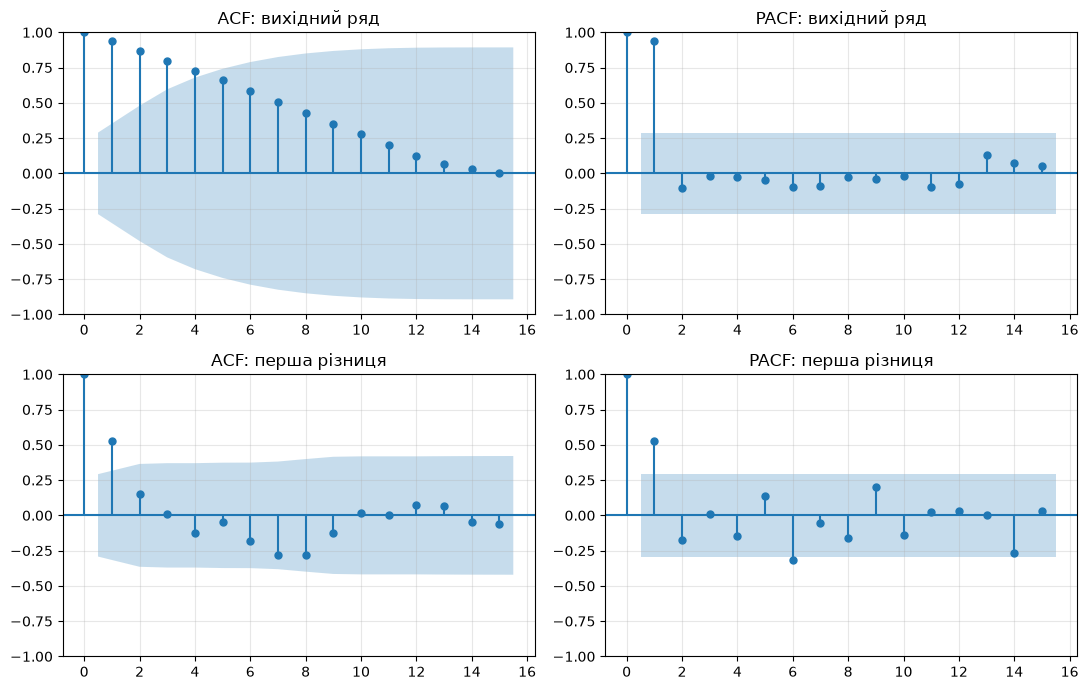

In [99]:
# Завдання 5. Стаціонарність
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

dy = y.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
plot_acf(y, lags=15, ax=axes[0, 0], title='ACF: вихідний ряд')
plot_pacf(y, lags=15, ax=axes[0, 1], title='PACF: вихідний ряд')
plot_acf(dy, lags=15, ax=axes[1, 0], title='ACF: перша різниця')
plot_pacf(dy, lags=15, ax=axes[1, 1], title='PACF: перша різниця')
plt.tight_layout()
plt.show()

In [100]:
rows = []
for name, x in [('вихідний ряд', y), ('перша різниця', dy)]:
    p_adf = adfuller(x, autolag='AIC')[1]
    p_kpss = kpss(x, regression='c', nlags='auto')[1]
    rows.append([name, round(p_adf, 4), round(p_kpss, 4)])
res_table = pd.DataFrame(rows, columns=['Ряд', 'ADF p (H0: нестаціонарний)', 'KPSS p (H0: стаціонарний)'])
print(res_table.to_string(index=False))
print('(KPSS повертає p лише в межах 0.01...0.10, тому 0.01 означає "не більше 0.01", а 0.10 - "не менше 0.10")')

bound = 1.96 / np.sqrt(len(dy))
print()
print('Межа значущості для ACF різниці: +-%.2f' % bound)
print('ACF різниці, лаги 1-6:', acf(dy, nlags=6)[1:].round(2))

          Ряд  ADF p (H0: нестаціонарний)  KPSS p (H0: стаціонарний)
 вихідний ряд                      0.9560                       0.01
перша різниця                      0.0056                       0.10
(KPSS повертає p лише в межах 0.01...0.10, тому 0.01 означає "не більше 0.01", а 0.10 - "не менше 0.10")

Межа значущості для ACF різниці: +-0.29
ACF різниці, лаги 1-6: [ 0.53  0.15  0.01 -0.12 -0.05 -0.18]


C:\Users\Admin\AppData\Local\Temp\ipykernel_8244\1660083432.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_adf = adfuller(x, autolag='AIC')[1]
C:\Users\Admin\AppData\Local\Temp\ipykernel_8244\1660083432.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  p_kpss = kpss(x, regression='c', nlags='auto')[1]
C:\Users\Admin\AppData\Local\Temp\ipykernel_8244\1660083432.py:4: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 

**Висновок до завдання 5:**

1. Графіки ACF і PACF побудовано до і після диференціювання. У вихідного ряду ACF спадає дуже повільно, а PACF на лагу 1 дорівнює 0,96: типова картина тренду. Після першої різниці в ACF значущий лише лаг 1 (0,53; межа ±0,29), у PACF значущий лаг 1 (0,54).
2. Таблиця p-значень:

| Ряд | ADF p (H0: нестаціонарний) | KPSS p (H0: стаціонарний) |
|---|---|---|
| вихідний | 0,956 | 0,01 |
| перша різниця | 0,006 | 0,10 |

3. Вихідний ряд: ADF p = 0,96 — нульову гіпотезу про нестаціонарність **не відхиляємо**; KPSS p = 0,01 — нульову гіпотезу про стаціонарність **відхиляємо**. Обидва тести кажуть: **нестаціонарний**. Перша різниця: ADF p = 0,006 — відхиляємо нестаціонарність; KPSS p ≥ 0,10 — стаціонарність не відхиляємо. Обидва кажуть: **стаціонарна**. Отже, потрібне одне диференціювання, d = 1.
4. Тести **узгоджуються**, тож пояснювати суперечність не потрібно. Примітка: KPSS повертає p лише між 0,01 і 0,10, тому ці числа — межі.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [101]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
vals = y.values           
N = len(vals)
K = 7                   
H = 3                

def naive(train, h):
    return np.repeat(train[-1], h)

def seasonal_naive(train, h):
    result = []
    for i in range(h):
        result.append(train[len(train) - 12 + i])
    return np.array(result)

def mean_forecast(train, h):
    return np.repeat(train.mean(), h)

def drift(train, h):
    slope = (train[-1] - train[0]) / (len(train) - 1)
    return train[-1] + slope * np.arange(1, h + 1)

def rolling_origin(method):
    # фолд f: навчання - усе до позиції -3*f, перевірка - наступні 3 точки
    true_all = []
    pred_all = []
    for f in range(1, K + 1):
        end = N - H * f
        train = vals[:end]
        true_all.extend(vals[end:end + H])
        pred_all.extend(method(train, H))
    return np.array(true_all), np.array(pred_all)

def metrics(true, pred):
    e = true - pred
    return [np.mean(np.abs(e)), np.sqrt(np.mean(e ** 2)), np.mean(np.abs(e / true)) * 100]

methods = {'Наївний': naive, 'Сезонний наївний': seasonal_naive, 'Середнє': mean_forecast, 'Дрейф': drift}
rows = []
for name, method in methods.items():
    true, pred = rolling_origin(method)
    rows.append([name] + metrics(true, pred))
base_table = pd.DataFrame(rows, columns=['Базис', 'MAE', 'RMSE', 'MAPE, %']).set_index('Базис')
print('Рухомий початок: %d фолдів по %d кроки, перевірено %d точок' % (K, H, len(true)))
print(base_table.round(3).to_string())
best_name = base_table['MAE'].idxmin()
print('Найкращий базис за MAE:', best_name)

Рухомий початок: 7 фолдів по 3 кроки, перевірено 21 точок
                    MAE   RMSE  MAPE, %
Базис                                  
Наївний           0.856  1.152    5.424
Сезонний наївний  3.441  3.923   21.441
Середнє           4.343  4.752   27.514
Дрейф             0.747  0.986    4.833
Найкращий базис за MAE: Дрейф


In [102]:
from sklearn.model_selection import train_test_split

vals = np.asarray(y, dtype=float).ravel()
idx = np.arange(len(vals))

train_idx, test_idx = train_test_split(
    idx, test_size=0.25, random_state=42
)
train_idx.sort()

errors = []
for t in test_idx:
    before = train_idx[train_idx < t]
    if len(before) >= 2:
        first, last = before[0], before[-1]
        slope = (vals[last] - vals[first]) / (last - first)
        prediction = vals[last] + slope * (t - last)
        errors.append(abs(vals[t] - prediction))

mae_random = np.mean(errors)
mae_rolling = base_table.loc['Дрейф', 'MAE']

print(f'MAE рухомого початку: {mae_rolling:.3f}')
print(f'MAE випадкового поділу 75/25: {mae_random:.3f}')

if mae_random > mae_rolling:
    print(f'Випадкова оцінка більша у {mae_random / mae_rolling:.2f} раза')
elif mae_random < mae_rolling:
    print(f'Випадкова оцінка менша у {mae_rolling / mae_random:.2f} раза')
else:
    print('Оцінки однакові')

MAE рухомого початку: 0.747
MAE випадкового поділу 75/25: 0.192
Випадкова оцінка менша у 3.89 раза


**Висновок до завдання 6:**
Найкращий — **дрейф** (з причини того, що ряд має сильний стійкий тренд (F_T = 0,99)). Найкращий прогноз — останнє значення плюс середній приріст. Наївний трохи гірший, бо ігнорує зростання й постійно занижує. Сезонний наївний бере ціну річної давнини, коли вона була набагато нижчою (у 2017 році вона була на 25–40 % нижча), тому більше помиляється. Середнє бере старі низькі ціни, тому ще гірше. Висновок: у цьому ряді важливий рівень і напрям, а не сезон.

Щодо способу поділу, то випадковий поділ **занижує помилку у 3-4 рази**. Причина: тестові місяці оточені навчальними, тож прогноз майже завжди на 1 крок і часто «підглядає в майбутнє». У реальному використанні майбутнього ми не знаємо, тому чесна оцінка — рухомий початок.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

p = 1 - Модель використовує одне попереднє значення диференційованого ряду для прогнозування.
d = 1 - Перед моделюванням обчислюється перша різниця
q = 1 - Модель враховує помилку прогнозу на одному попередньому кроці.

c:\Users\Admin\anaconda3\envs\study\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


                              MAE   RMSE  MAPE, %
Базис                                            
Наївний                     0.856  1.152    5.424
Дрейф                       0.747  0.986    4.833
ARIMA(1,1,1)                0.683  0.926    4.372
ARIMA(1,1,0) - за ACF/PACF  0.710  0.957    4.521
ARIMA(0,1,1) - за ACF/PACF  0.699  0.978    4.492
ARIMA(1,1,1) краща за дрейф за MAE на 8.6 %


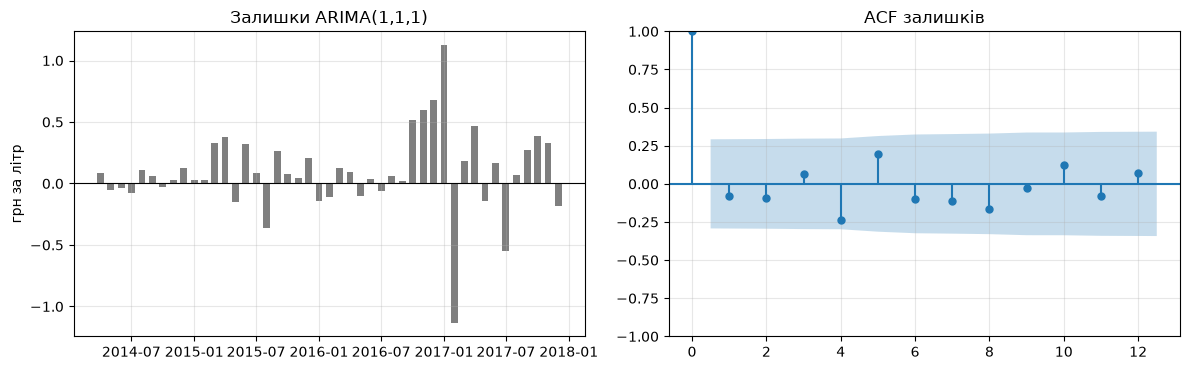

In [103]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

def arima111(train, h):
    return ARIMA(train, order=(1, 1, 1)).fit().forecast(h)

def arima110(train, h):
    return ARIMA(train, order=(1, 1, 0)).fit().forecast(h)

def arima011(train, h):
    return ARIMA(train, order=(0, 1, 1)).fit().forecast(h)

true_a, pred_a = rolling_origin(arima111)
true_b, pred_b = rolling_origin(arima110)
true_c, pred_c = rolling_origin(arima011)

cmp_table = base_table.loc[['Наївний', 'Дрейф']].copy()
cmp_table.loc['ARIMA(1,1,1)'] = metrics(true_a, pred_a)
cmp_table.loc['ARIMA(1,1,0) - за ACF/PACF'] = metrics(true_b, pred_b)
cmp_table.loc['ARIMA(0,1,1) - за ACF/PACF'] = metrics(true_c, pred_c)
print(cmp_table.round(3).to_string())
gain = (1 - cmp_table.loc['ARIMA(1,1,1)', 'MAE'] / cmp_table.loc['Дрейф', 'MAE']) * 100
print('ARIMA(1,1,1) краща за дрейф за MAE на %.1f %%' % gain)

# залишки моделі (1,1,1) на всьому ряді; перший залишок пропускаємо
model = ARIMA(vals, order=(1, 1, 1)).fit()
residuals = pd.Series(model.resid[1:], index=y.index[1:])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(residuals.index, residuals.values, width=20, color='tab:gray')
axes[0].axhline(0, color='black', lw=0.8)
axes[0].set_title('Залишки ARIMA(1,1,1)')
axes[0].set_ylabel('грн за літр')
plot_acf(residuals, lags=12, ax=axes[1], title='ACF залишків')
plt.tight_layout()
plt.show()

**Висновок до завдання 7:**

1. ARIMA(1,1,1) на рухомому початку: **MAE = 0,683, RMSE = 0,926, MAPE = 4,37 %**.
2. **Мій порядок за ACF/PACF.** d = 1. Після диференціювання значущий лише лаг 1 і в ACF, і в PACF: обидві функції «обриваються» після першого лага. Тому достатньо одного члена: підходить (1,1,0) або (0,1,1).
3. **Порівняння з найкращим базисом (дрейф):** ARIMA(1,1,1) краща за MAE на 8,6 %. Від наївного — краща на 20 % за MAE. ARIMA виграє за всіма трьома метриками, але перевага не є дуже значною. Простіші (0,1,1) і (1,1,0) дають менший виграш (за RMSE майже нічого: 0,978 і 0,957 проти 0,986). Тому право на існування в ARIMA **умовне**: вона трохи краща за дрейф, але статистично довести перевагу на 21 точці не вдається.
4. Помітної часової структури в залишках не видно, і модель, схоже, врахувала основну автокореляційну залежність ряду. Водночас є кілька значних відхилень залишків, зокрема у 2017 році, тому окремі аномальні коливання модель не пояснює.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

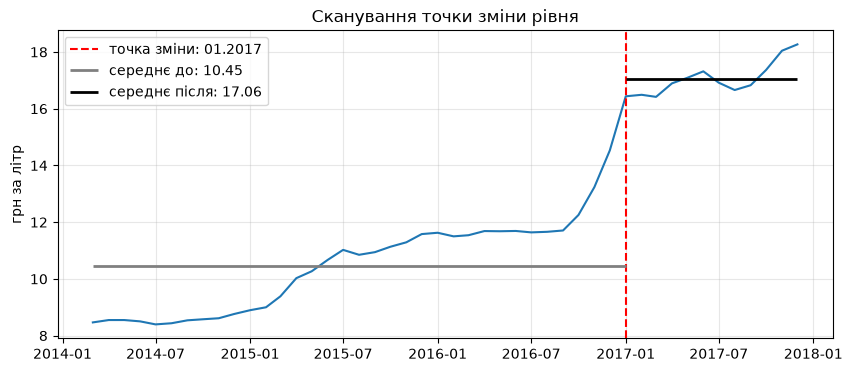

Дата (перший місяць "після"): 01.2017
t-статистика: -20.2
Середнє до: 10.45 грн, після: 17.06 грн, різниця 6.61 грн
Критичне |t| (5 %): 2.02 -> значуща
Розмах сезонної складової (завд. 4): 3.13 грн
Мінімум після точки: 16.42 грн; максимум до неї: 14.53 грн
Зміна у січні 2017: 1.91 грн = 4.8 стандартних відхилень місячних змін


In [104]:
# Завдання 8. Точка зміни режиму
from scipy import stats

MIN_SIDE = 6      # з кожного боку мінімум 6 точок
best_i, best_t = None, 0
for i in range(MIN_SIDE, N - MIN_SIDE):
    before, after = vals[:i], vals[i:]
    t_stat = stats.ttest_ind(before, after, equal_var=False)[0]
    if abs(t_stat) > abs(best_t):
        best_i, best_t = i, t_stat

cp_date = y.index[best_i]
mean_before = vals[:best_i].mean()
mean_after = vals[best_i:].mean()
t_crit = stats.t.ppf(1 - 0.05 / 2, df=N - 2)   # звичайний поріг 5 %

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(y.index, y.values, color='tab:blue')
ax.axvline(cp_date, color='red', ls='--', label='точка зміни: ' + cp_date.strftime('%m.%Y'))
ax.hlines(mean_before, y.index[0], cp_date, color='gray', lw=2, label='середнє до: %.2f' % mean_before)
ax.hlines(mean_after, cp_date, y.index[-1], color='black', lw=2, label='середнє після: %.2f' % mean_after)
ax.set_title('Сканування точки зміни рівня')
ax.set_ylabel('грн за літр')
ax.legend()
plt.show()

print('Дата (перший місяць "після"): %s' % cp_date.strftime('%m.%Y'))
print('t-статистика: %.1f' % best_t)
print('Середнє до: %.2f грн, після: %.2f грн, різниця %.2f грн' % (mean_before, mean_after, mean_after - mean_before))
print('Критичне |t| (5 %%): %.2f -> %s' % (t_crit, 'значуща' if abs(best_t) > t_crit else 'НЕ значуща'))

# відмінність від сезонності
print('Розмах сезонної складової (завд. 4): %.2f грн' % (seasonal.max() - seasonal.min()))
print('Мінімум після точки: %.2f грн; максимум до неї: %.2f грн' % (vals[best_i:].min(), vals[:best_i].max()))
jump = change['2017-01-01']
print('Зміна у січні 2017: %.2f грн = %.1f стандартних відхилень місячних змін' % (jump, jump / change.std()))

**Висновок до завдання 8:**

Знайдена дата точки зміни рівня -  **січень 2017**. t-статистика = **−20,2**, середнє до = **10,45 грн**, після = **17,06 грн**, різниця 6,61 грн.
Точка значуща: |t| = 20,2 набагато перевищує критичне значення 2,02 (рівень 5 %). Навіть з урахуванням того, що ми шукали найкращий розріз серед багатьох кандидатів (що завищує t), перевищення майже десятикратне, тому це не випадковий артефакт пошуку.

Це саме зсув рівня, а не сезон, з декількох причин:
- Зсув рівня більш ніж удвічі перевищує весь розмах сезонної складової STL. Сезонні коливання такого масштабу дати не можуть.
- Мінімальна ціна після точки (16,42 грн) вища за максимальну до неї (14,53 грн): ряд не повернувся на старий рівень, а перейшов на новий. Сезонний пік за визначенням повертається назад.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [105]:
# Завдання 9. Рецензія на чужий аналіз
bad = prices[(prices['ринок'] == 'Vinnytsia') & (prices['товар'] == 'Buckwheat grits - Retail')] \
    .sort_values('date').set_index('date')['ціна']

# Помилка клітинки 2: «пропусків немає»
bad_grid = bad.reindex(pd.date_range('2014-03-01', '2017-12-01', freq='MS'))
print('Автор нарахував спостережень:', len(bad), '· насправді місяців у періоді:', len(bad_grid))
print('Пропуск, який автор не побачив:',
      ', '.join(d.strftime('%m.%Y') for d in bad_grid[bad_grid.isna()].index))
print()

# Помилка клітинки 4: порівняння MAE в гривнях для товарів з різними цінами
for name, good in [('гречка', 'Buckwheat grits - Retail'), ('яловичина', 'Meat (beef) - Retail')]:
    x = prices[(prices['ринок'] == 'Vinnytsia') & (prices['товар'] == good)] \
        .sort_values('date')['ціна'].values
    err = np.abs(np.diff(x))
    print('%-10s середня ціна %6.2f грн · MAE %.2f грн · MAPE %.1f%%'
          % (name, x.mean(), err.mean(), (err / x[:-1]).mean() * 100))
print('→ у гривнях гірша яловичина, у відсотках — навпаки, гречка втричі гірша')
print()

# Помилка клітинки 10: висновок «ціна продовжить зростати»
print('Остання фактична ціна: %.2f грн' % bad.iloc[-1])
print('Прогноз автора на грудень 2018: 8.95 грн → це падіння, а не зростання')

Автор нарахував спостережень: 45 · насправді місяців у періоді: 46
Пропуск, який автор не побачив: 08.2017

гречка     середня ціна  21.32 грн · MAE 1.38 грн · MAPE 7.1%
яловичина  середня ціна  78.47 грн · MAE 1.51 грн · MAPE 2.0%
→ у гривнях гірша яловичина, у відсотках — навпаки, гречка втричі гірша

Остання фактична ціна: 17.67 грн
Прогноз автора на грудень 2018: 8.95 грн → це падіння, а не зростання


**Висновок до завдання 9:**

Нумерація клітинок: порядковий номер у файлі, рахуючи з 0 (markdown-клітинки теж). Числа в колонці «Суть» перевірено в клітинці вище.

| № | Клітинка | Суть помилки | Чим небезпечна |
|---|---|---|---|
| 1 | 3 (розділ 1) | «Пропусків немає»: `isna()` не бачить пропущеного **рядка**. У ряді 45 з 46 місяців (немає 08.2017); сітку `grid` створено, але не використано, `reindex` немає. | Ряд нерівномірний, а ACF, STL з періодом 12, `shift(12)` та ARIMA вважають його рівномірним: «12 спостережень» ≠ 12 місяців. |
| 2 | 5 (розділ 2) | Висновок про «різке зниження купівельної спроможності» з двох крайніх точок номінальних цін. Ще й «у кілька разів», хоча зростання у 2,47 раза. | Без інфляції й доходів про купівельну спроможність судити не можна; дві точки не показують динаміку. |
| 3 | 7 (розділ 3) | MAE у гривнях порівнюють для товарів із різним рівнем цін (гречка ~21 грн, яловичина ~78 грн). | Відносно рівня цін наївний прогноз гречки помиляється на 6,5 %, а яловичини на 1,9 %, тобто висновок **протилежний**. Потрібна відносна метрика (MAPE, MASE). |
| 4 | 9 (розділ 4) | Кореляція **рівнів** двох трендових рядів (r = 0,996) і висновок, що ціни у Львові «визначають» ціни у Вінниці. | Спільний тренд дає кореляцію сам по собі (хибна кореляція), а кореляція не є причинністю. Навіть у різницях r = 0,94, бо діє спільний чинник (девальвація, загальний попит). |
| 5 | 11 (розділ 5) | «STL виділив сезон, отже ряд сезонний»; сили сезонності F_S немає. Далі кажуть «використовуємо сезонні моделі», але ARIMA потім несезонна. | STL завжди повертає сезонну складову. Без F_S і порога висновок не обґрунтований, а висновок і подальші дії суперечать одне одному. |
| 6 | 13 (розділ 6) | **Інверсія ADF**: p = 0,233 > 0,05 означає, що H0 (нестаціонарність) не відхилено, а написано «ряд стаціонарний». Немає KPSS. Далі взято різницю **двічі** без перевірки, чи вистачить однієї. | Хибне діагностування стаціонарності псує всю подальшу модель. Зайве диференціювання додає шум і дає ненадійні прогнози. |
| 7 | 15 (розділ 7) | Аномалії шукають у **вихідному** ряді з трендом, а не в залишках після зняття тренду й сезону. Поріг 1,3σ, хоча заголовок і текст кажуть 2σ (при 2σ — 0 точок, при 1,3σ — 12). Середнє й σ беруть по всьому ряду. | «Аномалії» — це просто початок і кінець тренду, а не нетипові події. Підміна порога робить результат довільним. |
| 8 | 17 (розділ 8) | **Випадковий** `train_test_split` для часового ряду; у навчальній вибірці 33 точки з розривами в датах, а ARIMA вважає їх сусідніми місяцями. Прогноз порівнюють із `np.sort(y_te)`: відсортовані факти не відповідають датам прогнозу. Лише один поділ. | Порушено порядок часу, є витік майбутнього, а MAE — просто різниця двох розрізнених наборів чисел. Оцінка не має сенсу. |
| 9 | 17 (розділ 8) | Базис — лише сезонний наївний (MAE 9,2 на всьому ряді), а наївного немає: його MAE 1,38 грн. MAE ARIMA 8,73 грн — це **41 %** середньої ціни (21,3 грн), у ~6 разів гірше за наївний. Висновок «висока точність» хибний. | Порівнюють на різних вибірках і зі слабким базисом; погана модель виглядає хорошою. |
| 10 | 19 (розділ 9) | Прогноз робить інша модель, **ARIMA(2,2,1)**, яку ніхто не перевіряв (перевіряли (1,1,1)); порядок не обґрунтовано. Прогноз на грудень 2018 = **8,95 грн**, а остання ціна 17,67 грн, тобто прогноз **падає**, а висновок каже «продовжить зростати». Інтервалів немає, горизонт 12 міс. при 45 точках. | Висновок суперечить власному числу; d = 2 екстраполює квадратичний тренд; неперевірена модель і довгий горизонт без невизначеності вводять в оману. |
| 11 | 21 (розділ 10) | Стовпчикова діаграма з урізаною віссю (`ylim` від 24,76 замість 0). | Довжина стовпчика має відповідати значенню. Тут перший стовпчик майже нульовий, і зростання на 41 % виглядає як у рази більше. (Сам висновок про зростання правильний.) |
| 12 | 1 (імпорт) | `warnings.filterwarnings('ignore')` приховує всі попередження. | Разом із ними зникають попередження про збіжність і нестаціонарні початкові параметри ARIMA. |
| 13 | 22 (висновки) | Підсумки повторюють хибні тези: «стаціонарний», «ціни у Львові визначають», «висока точність», «у кілька разів». | Читач бачить лише висновки й ухвалює рішення на хибних підставах. |

**Як виправити три найсерйозніші помилки.**

* **№ 6 (ADF).** Читати p правильно: p > 0,05 → нестаціонарний. Додати KPSS; брати першу різницю (`s.diff().dropna()`) і перевіряти обидва тести на ній. Другу різницю брати лише якщо перша не стаціонарна.
* **№ 8 і 9 (оцінювання).** Замість випадкового поділу використати ретроспективну перевірку з рухомим початком (як у завданні 6): навчання завжди **до** тестових місяців, прогноз тієї ж довжини, середнє по всіх фолдах. Порівнювати з **наївним** і дрейфом на тих самих фолдах, а похибку подавати у відсотках (MAPE).
* **№ 1 (пропуск).** Перед аналізом побудувати повну сітку (`series.reindex(grid)`), побачити NaN, заповнити (наприклад, лінійно) і лише потім робити STL, ACF, ARIMA.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [106]:
# Завдання 10. Експорт ряду для Orange
export = pd.DataFrame({'date': y.index.strftime('%Y-%m-%d'), 'price': y.values})
export.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

check = pd.read_csv('ряд_для_orange.csv')
print('Стовпці:', list(check.columns))
print('Рядків даних:', len(check), '| порожніх значень:', int(check.isna().sum().sum()))
print('Перший і останній рядок:', check['date'].iloc[0], check['date'].iloc[-1])
print('Тип price:', check['price'].dtype, '| значення за 2017-08-01:', check.loc[check['date'] == '2017-08-01', 'price'].iloc[0])
print()
print(check.head(3).to_string(index=False))

Стовпці: ['date', 'price']
Рядків даних: 46 | порожніх значень: 0
Перший і останній рядок: 2014-03-01 2017-12-01
Тип price: float64 | значення за 2017-08-01: 16.65781893850446

      date  price
2014-03-01 8.4667
2014-04-01 8.5500
2014-05-01 8.5500


**Висновок до завдання 10:**

Файл `ряд_для_orange.csv` збережено. Перевірка після повторного читання: стовпці `date` та `price`, **46 рядків даних**, **0 порожніх значень**; дати у форматі `РРРР-ММ-ДД` від 2014-03-01 до 2017-12-01 (перше число місяця); `price` має числовий тип. Значення за 2017-08-01 — 16,6578 (заповнений кубічним сплайном), тому в Python і Orange дані **однакові**. Кодування UTF-8, роздільник — кома.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

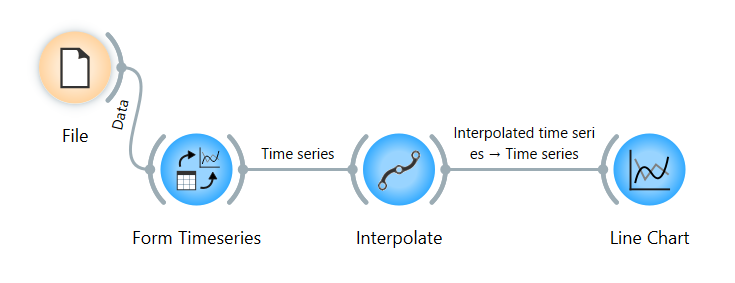

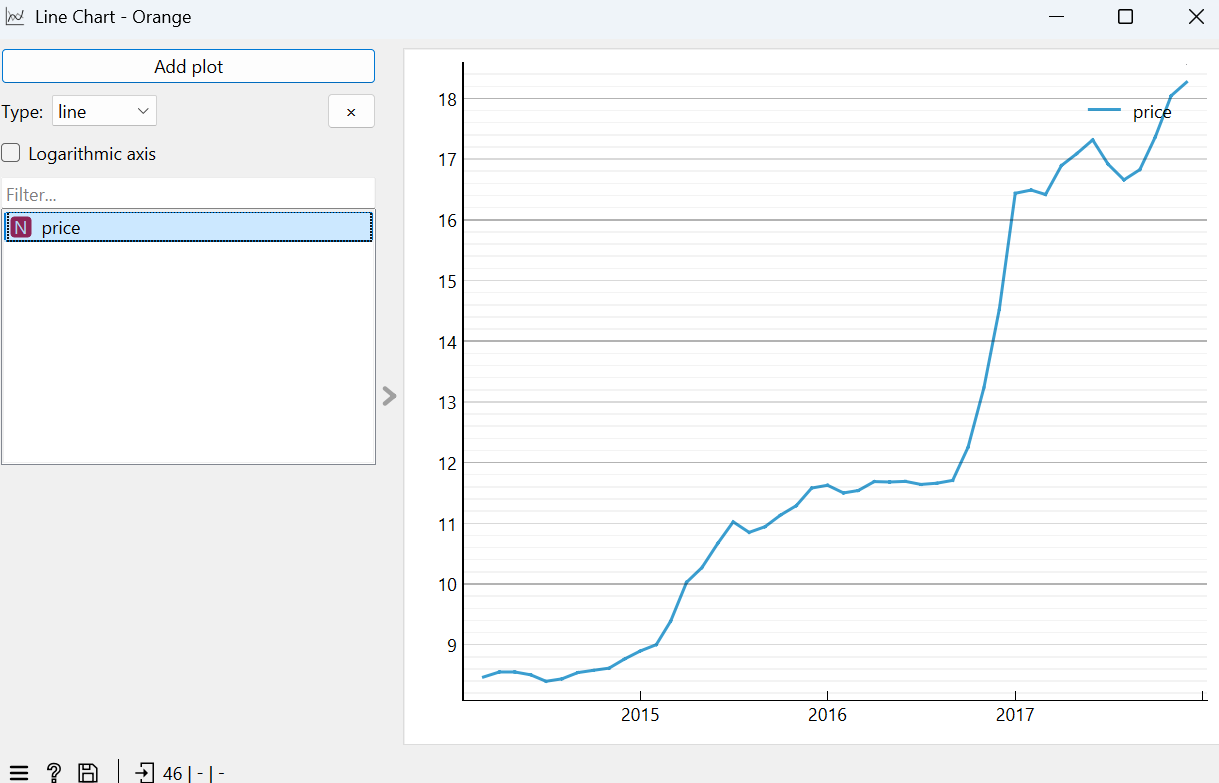

**Висновок до завдання 11:**

Потік File → As Timeseries → Interpolate → Line Chart побудовано; віджет File підтверджує, що завантажено 46 instances, 2 features (no missing values), де date розпізнано як datetime, а price — як numeric. Line Chart у Orange повторює графік 1 із завдання 3: та сама крива - межі збігаються.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

In [107]:
a = acf(y, nlags=35)
print('ACF  лаг 1: %.2f, лаг 33: %.2f' % (a[1], a[33]))

ACF  лаг 1: 0.94, лаг 33: -0.44


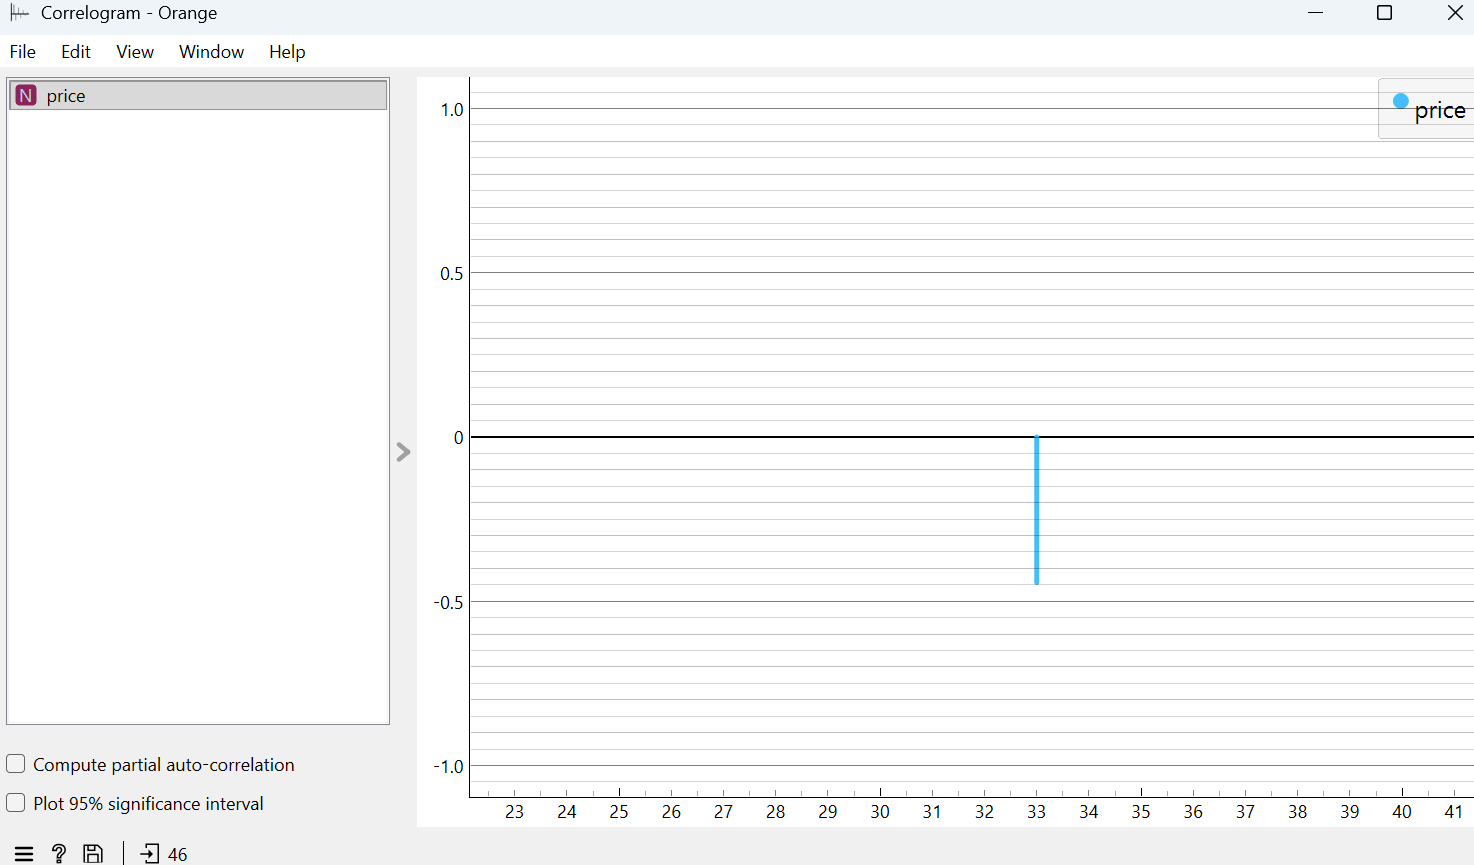

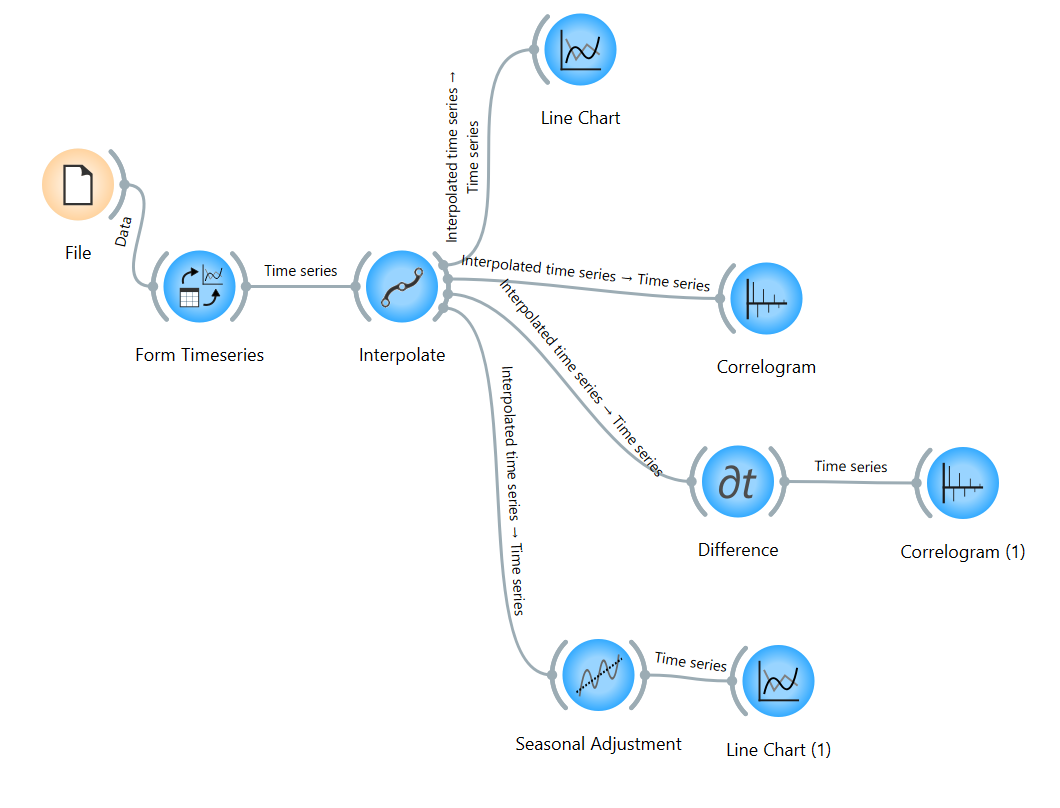

**Висновок до завдання 12:**
У Orange до виходу Interpolate підключено Correlogram, Difference (First order difference, shift 1) і Seasonal Adjustment

Correlogram в Orange відобразив лише частину лагів. Числове значення на відображених лагах збігається з ACF statsmodels. 
Скоригований ряд майже не відрізняється від вихідного: це ще раз показує, що сезонність тут мала.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [108]:
# Завдання 13. Модель і оцінювання (ARIMA(1,1,1), Model Evaluation: 7 фолдів, 3 кроки)
# Чому типові налаштування не працюють
n_folds_default, steps, lag = 20, 3, 1
print()
print('Типові налаштування: %d фолдів x %d кроки + лаг %d = %d' % (n_folds_default, steps, lag, n_folds_default * steps + lag))
print('Довжина ряду: %d  ->  %d > %d, перевірка не пройдена' % (N, n_folds_default * steps + lag, N))
print('Максимум фолдів при 3 кроках: (%d - %d) // %d = %d' % (N, lag, steps, (N - lag) // steps))


Типові налаштування: 20 фолдів x 3 кроки + лаг 1 = 61
Довжина ряду: 46  ->  61 > 46, перевірка не пройдена
Максимум фолдів при 3 кроках: (46 - 1) // 3 = 15


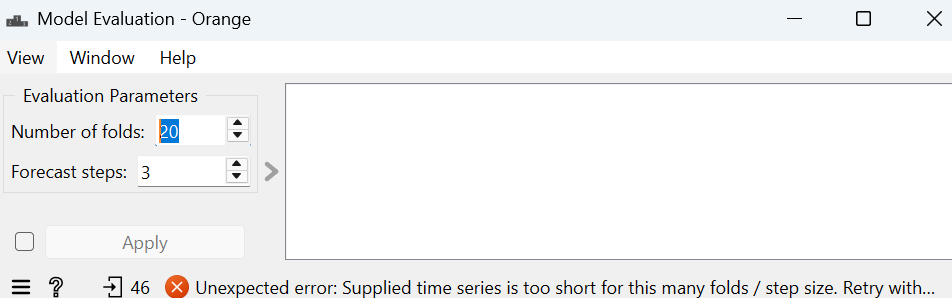

При 20 фолдах Orange відмовляється рахувати: «Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer…» 

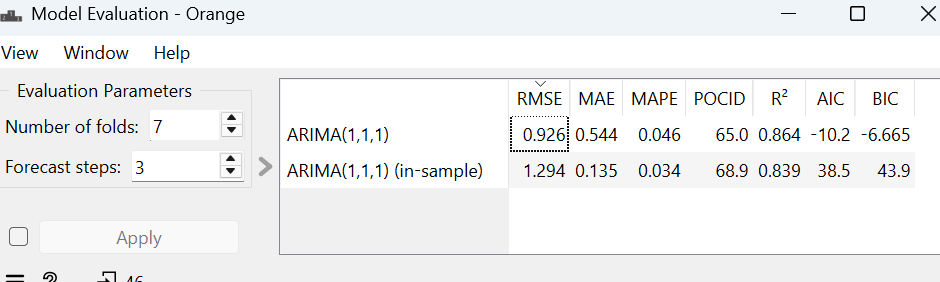

При 7 фолдах і 3 кроках віджет рахує. Верхній рядок таблиці (ARIMA(1,1,1)): RMSE 0.926; MAE 0.544; MAPE 0,046; 

Рядок «(in-sample)» — це оцінка на всьому ряді без ретроспективної перевірки, тому далі не використовується.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [109]:
# Завдання 14. Відтворення чотирьох метрик Orange у Python
true, pred = rolling_origin(arima111)
e = true - pred

rmse_py = np.sqrt(np.sum(e ** 2) / len(e))                  
mae_py = np.median(np.abs(e))                                 
mape_py = np.mean(np.abs(e)) / np.mean(np.abs(true))         
pocid_py = 100 * np.mean(np.diff(true) * np.diff(pred) > 0)   

rows = [
    ['RMSE', 0.926, rmse_py],
    ['MAE', 0.544, mae_py],
    ['MAPE', 0.046, mape_py],
    ['POCID', 65.0, pocid_py], #100 - частка збігів знака зміни
]
tab14 = pd.DataFrame(rows, columns=['Метрика', 'Orange', 'Python (відтворення)'])
tab14['Збіг до 3-го знака'] = np.abs(tab14['Orange'] - tab14['Python (відтворення)']) < 0.0005
print(tab14.round(4).to_string(index=False))


Метрика  Orange  Python (відтворення)  Збіг до 3-го знака
   RMSE   0.926                0.9258                True
    MAE   0.544                0.5441                True
   MAPE   0.046                0.0456                True
  POCID  65.000               65.0000                True


**Висновок до завдання 14:**

Перш ніж порівнювати числа з двох інструментів, треба перевірити: (а) що однакові дані й однакові фолди та горизонт; (б) що однакова модель і порядок; (в) **означення кожної метрики** — середнє чи медіана, відносно чого, у відсотках чи частках; (г) одиниці. Назва метрики нічого не гарантує, тому формулу слід читати у вихідному коді. Спільна назва ≠ спільна величина.

Значення RMSE та інших метрик повністю збігаються, оскільки в обох середовищах використовується однакова формула. Усі чотири числа Orange відтворено в Python за формулами з методичних вказівок; 

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [110]:
actual_change = np.diff(true_a)
predicted_change = np.diff(pred_a)

actual_direction = np.sign(actual_change)
predicted_direction = np.sign(predicted_change)

directions = [1, -1]
labels = ['Зросла', 'Впала']
counts = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(actual_direction, predicted_direction):
    if actual != 0 and predicted != 0:
        row = 0 if actual > 0 else 1
        column = 0 if predicted > 0 else 1
        counts[row, column] += 1

direction_matrix = pd.DataFrame(
    counts,
    index=pd.Index(labels, name='Насправді'),
    columns=pd.Index(labels, name='Передбачено')
)

print('Матриця напрямків:')
print(direction_matrix)
print()

correct = np.sum(actual_change * predicted_change > 0)
total = len(actual_change)
pocid_python = 100 * correct / total

pocid_orange = 65.0  

print(f'Правильних напрямків: {correct} із {total}')
print(f'POCID у Python: {pocid_python:.1f}%')
print(f'POCID в Orange:  {pocid_orange:.1f}%')
print(f'Значення збігаються: {np.isclose(pocid_python, pocid_orange)}')

Матриця напрямків:
Передбачено  Зросла  Впала
Насправді                 
Зросла            9      3
Впала             4      4

Правильних напрямків: 13 із 20
POCID у Python: 65.0%
POCID в Orange:  65.0%
Значення збігаються: True


**Висновок до завдання 15:**

Правильні передбачення: (9 + 4) / 20 = **65,0 %**, що збігається з POCID у Orange

**Для рішення «купувати зараз чи чекати» модель непридатна.** Точність 64–65 % лише трохи краща за підкидання монети, і вона **нижча за тривіальну відповідь «завжди зросте»**. Падіння ціни модель у межах фолдів **жодного разу** правильно не передбачила (комірка «факт впала / прогноз впала» дорівнює 0). 

---
# Загальний висновок
Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
**Сезонність є, але помірна.** Сила сезонності F_S = 0,787 при порозі 0,6: максимум у січні, мінімум у вересні, розмах 1,22 грн (≈10 % рівня), що узгоджується з літнім спадом цін на графіку. Проте тренд домінує (F_T = 0,99), а сезонна складова мала.


1. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
**Найкращий метод.** Серед базисів найкращий дрейф (MAE 0,747 проти 0,856 у наївного; сезонний наївний і середнє у 4–6 разів гірші). ARIMA(1,1,1) виграє за всіма метриками (MAE 0,683, −8,6 % до дрейфу).

1. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
**Точка зміни режиму є:** січень 2017; ціни після неї всі вищі за ціни до неї. Це підйом на 40 % за жовтень 2016 — січень 2017 без повернення. Можливе зовнішнє пояснення — дефіцит молока-сировини.

1. Чому однаково названі метрики у двох середовищах дали різні числа?
**Чому метрики різні.** Назви однакові, а означення ні: MAE в Orange — медіана модуля похибки, а не середнє; MAPE — mean|e|/mean|y| у частках, а не середнє |e/y| у відсотках; POCID вимірює напрям, а не величину. RMSE збіглася, бо означення однакове. Усі чотири числа відтворено в Python до 3-го знака.

1. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?
. **Обмеження 46 спостережень.** Лише 3,8 сезонного циклу: стабільність сезонності встановити не можна. 21 тестова точка (7 фолдів) і один великий стрибок, тож різниця між ARIMA та дрейфом нічого не доводить; прогноз напряму спирається на 7 незалежних знаків.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Gemini |
| Для яких саме завдань | 3, 4, 5, 10, 11, 12, 13, 14 |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | код, пояснення, виправлення помилок |
| Що ви змінили у згенерованому результаті й чому | інколи генерувався надлишковий код, то його забирала, інколи щось треба було по-інакшому висвітлити|
| Що з отриманого ви **перевірили самостійно** і яким способом | самостійно звірила всі метрики якості моделей і контрольні значення часового ряду шляхом порівняння результатів обчислень у середовищі Orange із програмним виводом
 |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | - |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________